ANN Classification Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



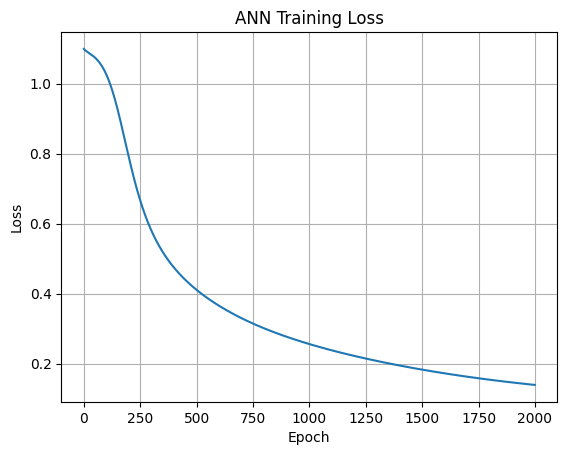

In [ ]:

# ANN using Backpropagation

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# 2. Convert class labels into one-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y
)

# 4. Normalize the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Define activation functions
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# 6. Initialize weights and biases
np.random.seed(42)
input_size = X_train.shape[1]
hidden_size = 10
output_size = y_train.shape[1]

W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))

learning_rate = 0.05
epochs = 2000
loss_history = []

# 7. Train the neural network using backpropagation
for epoch in range(epochs):

    # Forward propagation
    hidden_input = np.dot(X_train, W1) + b1
    hidden_output = sigmoid(hidden_input)

    output_input = np.dot(hidden_output, W2) + b2
    predicted_output = softmax(output_input)

    # Calculate categorical cross-entropy loss
    loss = -np.mean(
        np.sum(y_train * np.log(predicted_output + 1e-9), axis=1)
    )
    loss_history.append(loss)

    # Backpropagation: calculate output layer gradients
    output_error = (predicted_output - y_train) / X_train.shape[0]
    dW2 = np.dot(hidden_output.T, output_error)
    db2 = np.sum(output_error, axis=0, keepdims=True)

    # Backpropagation: calculate hidden layer gradients
    hidden_error = np.dot(output_error, W2.T) * (
        hidden_output * (1 - hidden_output)
    )
    dW1 = np.dot(X_train.T, hidden_error)
    db1 = np.sum(hidden_error, axis=0, keepdims=True)

    # Update weights and biases
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

# 8. Predict classes for test data
hidden_test = sigmoid(np.dot(X_test, W1) + b1)
output_test = softmax(np.dot(hidden_test, W2) + b2)
y_pred = np.argmax(output_test, axis=1)
y_actual = np.argmax(y_test, axis=1)

# 9. Evaluate the model
print("ANN Classification Accuracy:",
      round(accuracy_score(y_actual, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_actual, y_pred, target_names=iris.target_names))

# 10. Plot the training loss
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training Loss")
plt.grid(True)
plt.show()

First five rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Cluster assignments:
   Cluster
0        1
1        1
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        1

Number of data points in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


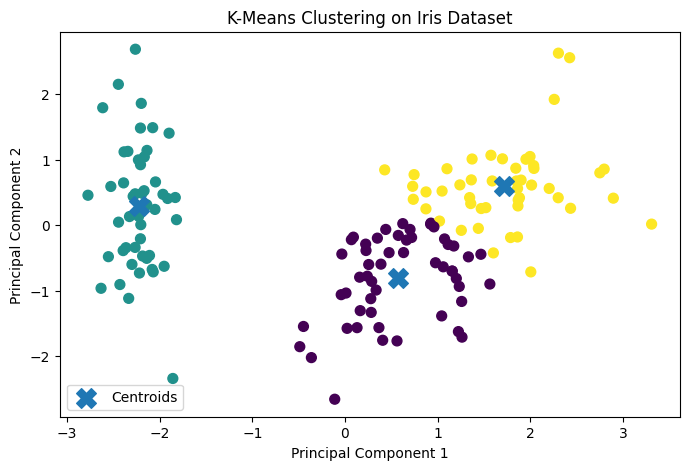

In [ ]:

# K-Means Clustering

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data

# 2. Convert dataset into a DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
print("First five rows of the dataset:")
print(df.head())

# 3. Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply the K-Means algorithm
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# 5. Get cluster labels
clusters = kmeans.labels_
df["Cluster"] = clusters

print("\nCluster assignments:")
print(df[["Cluster"]].head(10))

print("\nNumber of data points in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# 6. Reduce data to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 7. Visualize the clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=clusters, cmap="viridis", s=50
)
plt.scatter(
    pca.transform(kmeans.cluster_centers_)[:, 0],
    pca.transform(kmeans.cluster_centers_)[:, 1],
    marker="X", s=200, label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on Iris Dataset")
plt.legend()
plt.show()
